# Ablation study rapido (clasificacion multiclase, CIC-IDS2017)

Version ligera pensada para correr en **unos 6-10 minutos en Colab**: solo carga, limpia, selecciona las mismas `FEATURES` que el notebook completo y corre el ablation. No incluye EDA, busquedas de hiperparametros ni los modelos finales, y **no toca el test**.

Se quita **una pieza a la vez** del modelo completo y se mide el cambio en **F1 macro** y en el **recall por clase**. Cada configuracion se repite con **3 semillas** (cambian el split interno y el modelo). Una diferencia solo cuenta como efecto real si supera la desviacion estandar entre semillas.

Los hiperparametros del Random Forest y del SVM son fijos (no vienen de la busqueda), porque el ablation compara piezas del pipeline, no modelos optimizados.

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
warnings.filterwarnings('ignore')
T_TOTAL = time.perf_counter()

path = kagglehub.dataset_download("chethuhn/network-intrusion-dataset")
dfs = []
for f in glob.glob(os.path.join(path, "*.csv")):
    d = pd.read_csv(f)
    d.columns = d.columns.str.strip()      # los nombres traen espacios al inicio
    dfs.append(d)
df = pd.concat(dfs, ignore_index=True)
del dfs
print("Dataset completo:", df.shape)

Using Colab cache for faster access to the 'network-intrusion-dataset' dataset.
Dataset completo: (2830743, 79)


In [2]:
# Misma limpieza que en el notebook completo: inf -> NaN y se eliminan esas filas
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
df = df.loc[~df[num_cols].isna().any(axis=1)].reset_index(drop=True)
df[num_cols] = df[num_cols].astype('float32')     # menos memoria y mas velocidad
print("Shape despues de la limpieza:", df.shape)

Shape despues de la limpieza: (2827876, 79)


In [3]:
from sklearn.model_selection import train_test_split

df['Label_bin'] = (df['Label'] != 'BENIGN').astype(int)

def familia(etiqueta):
    if etiqueta == 'BENIGN':            return 'BENIGN'
    if etiqueta.startswith('DoS'):      return 'DoS'
    if etiqueta == 'DDoS':              return 'DDoS'
    if etiqueta == 'PortScan':          return 'PortScan'
    if etiqueta in ('FTP-Patator', 'SSH-Patator'): return 'Brute Force'
    if etiqueta.startswith('Web Attack'): return 'Web Attack'
    if etiqueta == 'Bot':               return 'Bot'
    return 'Raras'                      # Infiltration, Heartbleed

df['Label_multi'] = df['Label'].map(familia)
nombres_clases = df['Label_multi'].value_counts().index.tolist()
mapa_multi = {c: i for i, c in enumerate(nombres_clases)}
df['Label_multi_id'] = df['Label_multi'].map(mapa_multi)

# Mismo split y misma seleccion de features que el notebook completo (todo calculado SOLO en train)
SEED = 67
idx_tr, idx_te = train_test_split(df.index, test_size=0.2,
                                  stratify=df['Label_multi_id'], random_state=SEED)
train = df.loc[idx_tr]

cols_label = ['Label_bin', 'Label_encoded', 'Label_multi_id']
num_train = train.select_dtypes('number').drop(columns=cols_label, errors='ignore')
corr_bin = num_train.corrwith(train['Label_bin'])
cols_sel = corr_bin[corr_bin.abs() > 0.5].index.tolist()
if len(cols_sel) < 3:
    cols_sel = corr_bin.abs().sort_values(ascending=False).index[:8].tolist()

corr_cols = train[cols_sel].corr().abs()
a_eliminar = []
for i, c in enumerate(cols_sel):
    if c in a_eliminar:
        continue
    for c2 in cols_sel[i + 1:]:
        if c2 not in a_eliminar and corr_cols.loc[c, c2] > 0.95:
            a_eliminar.append(c2)
FEATURES = [c for c in cols_sel if c not in a_eliminar]
print(f"{len(FEATURES)} FEATURES:", FEATURES)
print("Eliminadas por redundancia:", a_eliminar)

# Solo se conserva lo necesario para el ablation (el test no se usa)
train = train[FEATURES + a_eliminar + ['Label_multi_id']].reset_index(drop=True)
y_train_multi = train['Label_multi_id'].values
inv_multi = {v: k for k, v in mapa_multi.items()}
del df, num_train, corr_cols
print("Train:", train.shape, f"| tiempo acumulado: {time.perf_counter() - T_TOTAL:.0f}s")

5 FEATURES: ['Bwd Packet Length Std', 'Avg Bwd Segment Size', 'Packet Length Std', 'Packet Length Variance', 'Fwd IAT Std']
Eliminadas por redundancia: ['Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Max Packet Length']
Train: (2262300, 9) | tiempo acumulado: 86s


In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score

def indices_estratificados(y, n, minimo_por_clase=0, seed=SEED):
    y = np.asarray(y)
    if n >= len(y):
        return np.arange(len(y))
    rng = np.random.default_rng(seed)
    clases, conteos = np.unique(y, return_counts=True)
    cuota = np.round(conteos / conteos.sum() * n).astype(int)
    cuota = np.maximum(cuota, np.minimum(minimo_por_clase, conteos))
    cuota = np.minimum(cuota, conteos)
    idx = [rng.choice(np.where(y == c)[0], size=q, replace=False) for c, q in zip(clases, cuota)]
    idx = np.concatenate(idx)
    rng.shuffle(idx)
    return idx

SEEDS = [0, 1, 2]
ABL_N = 40_000        # submuestra estratificada del TRAIN (sube este valor si quieres mas precision)
RF_PARAMS = dict(n_estimators=60, max_depth=20, min_samples_leaf=2, max_features='sqrt')

idx_a = indices_estratificados(y_train_multi, ABL_N, 200)
A = train.iloc[idx_a]
ya = y_train_multi[idx_a]
clases_a = sorted(np.unique(ya))

def cols_con(*claves):
    return [c for c in FEATURES if any(k.lower() in c.lower() for k in claves)]

grupos = {'IAT': cols_con('IAT'),
          'Length / Size': cols_con('Length', 'Size'),
          'Flags': cols_con('Flag'),
          'Idle / Active': cols_con('Idle', 'Active'),
          'Packets': cols_con('Packets'),
          'Bytes': cols_con('Bytes')}
grupos = {g: c for g, c in grupos.items() if c}
for g, c in grupos.items():
    print(f"{g}: {c}")

configs = {'baseline': dict(cols=FEATURES, cw='balanced')}
for g, c in grupos.items():
    resto = [x for x in FEATURES if x not in c]
    if resto:
        configs[f'sin {g}'] = dict(cols=resto, cw='balanced')
configs['sin class_weight'] = dict(cols=FEATURES, cw=None)
if a_eliminar:
    configs['+ redundantes'] = dict(cols=FEATURES + a_eliminar, cw='balanced')

print(f"\n{len(configs)} configuraciones x {len(SEEDS)} semillas = {len(configs) * len(SEEDS)} entrenamientos")

IAT: ['Fwd IAT Std']
Length / Size: ['Bwd Packet Length Std', 'Avg Bwd Segment Size', 'Packet Length Std', 'Packet Length Variance']

5 configuraciones x 3 semillas = 15 entrenamientos


In [5]:
resultados_abl, recall_abl = [], {}
for nombre, cfg in configs.items():
    t0 = time.perf_counter()
    Xa = A[cfg['cols']].values
    f1s, recs = [], []
    for s in SEEDS:
        itr, iva = train_test_split(np.arange(len(A)), test_size=0.3, stratify=ya, random_state=s)
        m = RandomForestClassifier(n_jobs=-1, random_state=s, class_weight=cfg['cw'],
                                   **RF_PARAMS).fit(Xa[itr], ya[itr])
        p = m.predict(Xa[iva])
        f1s.append(f1_score(ya[iva], p, average='macro'))
        recs.append(recall_score(ya[iva], p, labels=clases_a, average=None, zero_division=0))
    resultados_abl.append({'config': nombre, 'n_features': len(cfg['cols']),
                           'F1_macro': np.mean(f1s), 'std': np.std(f1s),
                           'tiempo_s': time.perf_counter() - t0})
    recall_abl[nombre] = np.mean(recs, axis=0)
    print(f"{nombre:22s} F1 macro = {np.mean(f1s):.4f} +- {np.std(f1s):.4f}  ({time.perf_counter() - t0:.0f}s)")

tabla_abl = pd.DataFrame(resultados_abl).set_index('config')
base = tabla_abl.loc['baseline']
tabla_abl['delta'] = tabla_abl['F1_macro'] - base['F1_macro']
tabla_abl['efecto_real'] = tabla_abl['delta'].abs() > np.maximum(tabla_abl['std'], base['std'])
display(tabla_abl.round(4))

recall_df = pd.DataFrame(recall_abl, index=[inv_multi[c] for c in clases_a]).T
display(recall_df.round(3))

baseline               F1 macro = 0.7058 +- 0.0183  (5s)
sin IAT                F1 macro = 0.6551 +- 0.0212  (6s)
sin Length / Size      F1 macro = 0.2889 +- 0.0093  (4s)
sin class_weight       F1 macro = 0.8210 +- 0.0124  (4s)
+ redundantes          F1 macro = 0.7554 +- 0.0050  (6s)


,n_features,F1_macro,std,tiempo_s,delta,efecto_real
config,,,,,,
baseline,5,0.7058,0.0183,4.5679,0.0000,False
sin IAT,4,0.6551,0.0212,5.6607,-0.0507,True
sin Length / Size,1,0.2889,0.0093,3.6864,-0.4170,True
sin class_weight,5,0.8210,0.0124,4.3346,0.1152,True
+ redundantes,8,0.7554,0.0050,5.7671,0.0495,True


,BENIGN,DoS,PortScan,DDoS,Brute Force,Web Attack,Bot,Raras
baseline,0.765,0.981,0.993,0.944,0.789,0.589,0.950,0.758
sin IAT,0.748,0.709,0.993,0.627,0.783,0.989,0.989,0.727
sin Length / Size,0.249,0.609,0.995,0.478,0.222,0.217,0.189,0.152
sin class_weight,0.991,0.729,0.993,0.915,0.783,0.328,0.639,0.818
+ redundantes,0.836,0.986,0.993,0.996,0.800,0.633,0.961,0.848


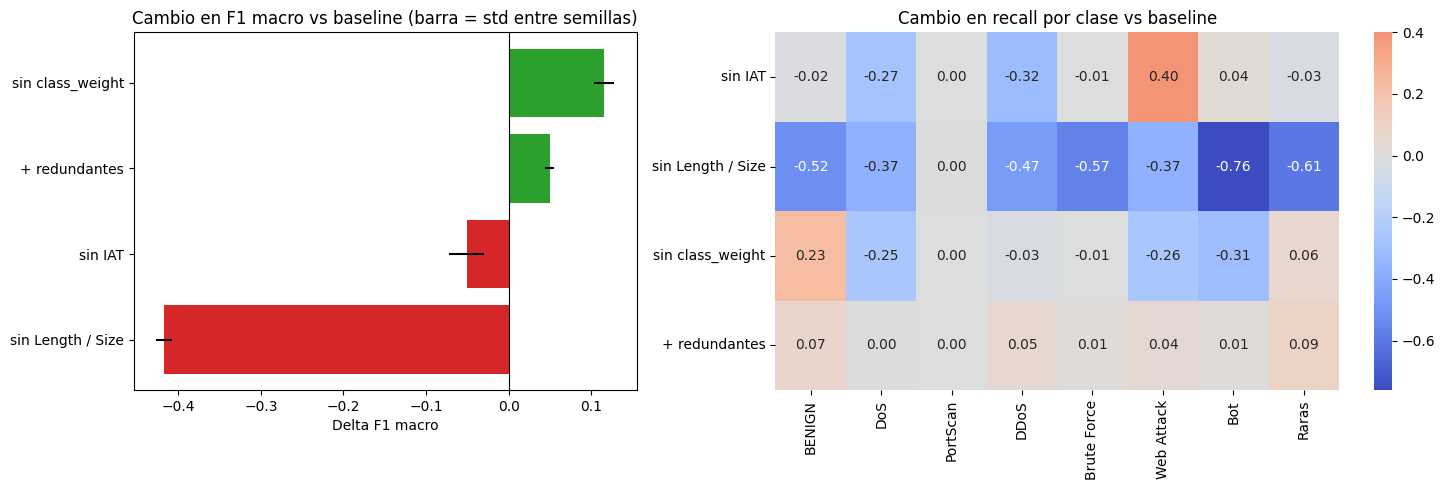

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.4]})

d = tabla_abl.drop('baseline')['delta'].sort_values()
axes[0].barh(d.index, d.values, xerr=tabla_abl.loc[d.index, 'std'].values,
             color=['tab:red' if v < 0 else 'tab:green' for v in d.values])
axes[0].axvline(0, color='k', lw=0.8)
axes[0].set_title('Cambio en F1 macro vs baseline (barra = std entre semillas)')
axes[0].set_xlabel('Delta F1 macro')

sns.heatmap(recall_df.drop('baseline') - recall_df.loc['baseline'],
            annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Cambio en recall por clase vs baseline')
plt.tight_layout()
plt.show()

### Ablation del escalado (SVM)

El SVM con kernel RBF depende de distancias, asi que es donde el escalado deberia importar. Se compara el pipeline completo (`log con signo` + `StandardScaler`) contra versiones sin una o sin ambas piezas, con hiperparametros fijos y una submuestra pequena (el SVM es cuadratico en el numero de filas).

completo (log + StandardScaler)    F1 macro = 0.5797 +- 0.0198
sin StandardScaler                 F1 macro = 0.6871 +- 0.0124
sin log                            F1 macro = 0.4640 +- 0.0189
sin escalado (crudo)               F1 macro = 0.3360 +- 0.0135


,F1_macro,std,tiempo_s,delta
config,,,,
completo (log + StandardScaler),0.5797,0.0198,2.5585,0.0000
sin StandardScaler,0.6871,0.0124,1.7568,0.1073
sin log,0.4640,0.0189,6.4572,-0.1158
sin escalado (crudo),0.3360,0.0135,10.6622,-0.2438


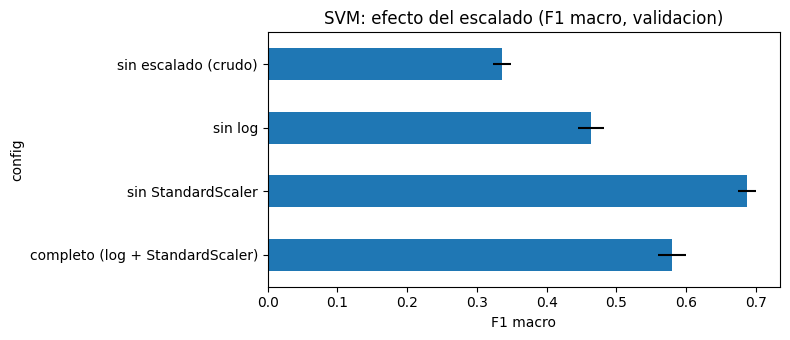

Tiempo total del notebook: 2.2 min


In [7]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

def log_signed(X):
    X = np.asarray(X, dtype=float)
    return np.sign(X) * np.log1p(np.abs(X))

SVM_ABL_N = 6_000
idx_b = indices_estratificados(y_train_multi, SVM_ABL_N, 100)
Xb, yb = train[FEATURES].values[idx_b], y_train_multi[idx_b]

def svm_pipe(log, escala, seed):
    pasos = []
    if log:
        pasos.append(FunctionTransformer(log_signed))
    if escala:
        pasos.append(StandardScaler())
    pasos.append(SVC(kernel='rbf', C=10, gamma=0.1, class_weight='balanced',
                     cache_size=500, random_state=seed))
    return make_pipeline(*pasos)

cfg_svm = {'completo (log + StandardScaler)': (True, True),
           'sin StandardScaler': (True, False),
           'sin log': (False, True),
           'sin escalado (crudo)': (False, False)}

filas_svm = []
for nombre, (log, escala) in cfg_svm.items():
    t0 = time.perf_counter()
    f1s = []
    for s in SEEDS:
        itr, iva = train_test_split(np.arange(len(Xb)), test_size=0.3, stratify=yb, random_state=s)
        m = svm_pipe(log, escala, s).fit(Xb[itr], yb[itr])
        f1s.append(f1_score(yb[iva], m.predict(Xb[iva]), average='macro'))
    filas_svm.append({'config': nombre, 'F1_macro': np.mean(f1s), 'std': np.std(f1s),
                      'tiempo_s': time.perf_counter() - t0})
    print(f"{nombre:34s} F1 macro = {np.mean(f1s):.4f} +- {np.std(f1s):.4f}")

tabla_svm = pd.DataFrame(filas_svm).set_index('config')
tabla_svm['delta'] = tabla_svm['F1_macro'] - tabla_svm.iloc[0]['F1_macro']
display(tabla_svm.round(4))

tabla_svm['F1_macro'].plot(kind='barh', xerr=tabla_svm['std'], figsize=(8, 3.5),
                           title='SVM: efecto del escalado (F1 macro, validacion)')
plt.xlabel('F1 macro')
plt.tight_layout()
plt.show()
print(f"Tiempo total del notebook: {(time.perf_counter() - T_TOTAL) / 60:.1f} min")

### Conclusiones del ablation (completar tras correr)

- **Que grupo de features aporta mas?** (barra mas negativa y `efecto_real` = True)
- **Alguna clase rara cae aunque el F1 macro casi no cambie?** (heatmap de recall)
- **Las features redundantes importaban?** (fila `+ redundantes`: si el delta es menor que la std, eliminarlas se justifica)
- **Escalado:** que paso del pipeline del SVM pesa mas, el log o el StandardScaler?
- **Limitaciones:** submuestra de 40.000 filas, 3 semillas, hiperparametros fijos, y grupos de features armados por nombre de columna.